In [26]:
import soccerdata as sd
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
#this line of code will download the data from understat.com for the English Premier League for the 2025/2026 season
understat = sd.Understat(leagues="ENG-Premier League", seasons="2025/2026")

[8/2/2026 4:25:30 PM] INFO     Saving cached data to C:\Users\malco\soccerdata\data\Understat        ]8;id=10473571;file://C:\Users\malco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=10473572;file://C:\Users\malco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\soccerdata\_common.py#250\250]8;;\

In [ ]:
#this line of code will download the player season stats for the English Premier League for the 2025/2026 season
player_season_stats = understat.read_player_season_stats()

In [ ]:
#this line of code will extract the player season stats for Manchester United from the player season stats dataframe
man_utd_data = player_season_stats.xs("Manchester United", level = "team")

In [ ]:
#this line of code will reset the index of the man_utd_data dataframe so that the player names are a column instead of an index
man_utd_data = man_utd_data.reset_index()

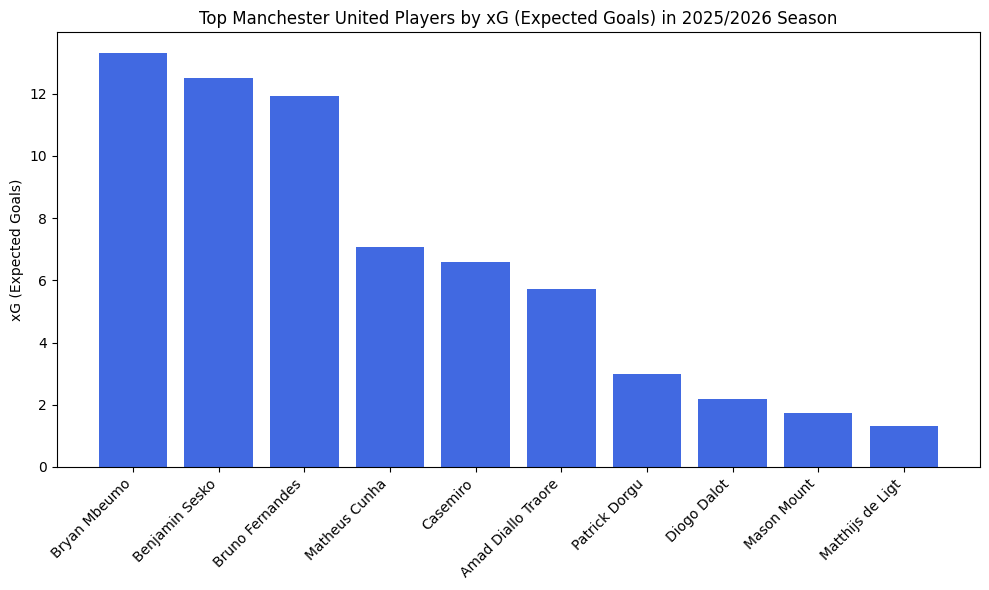

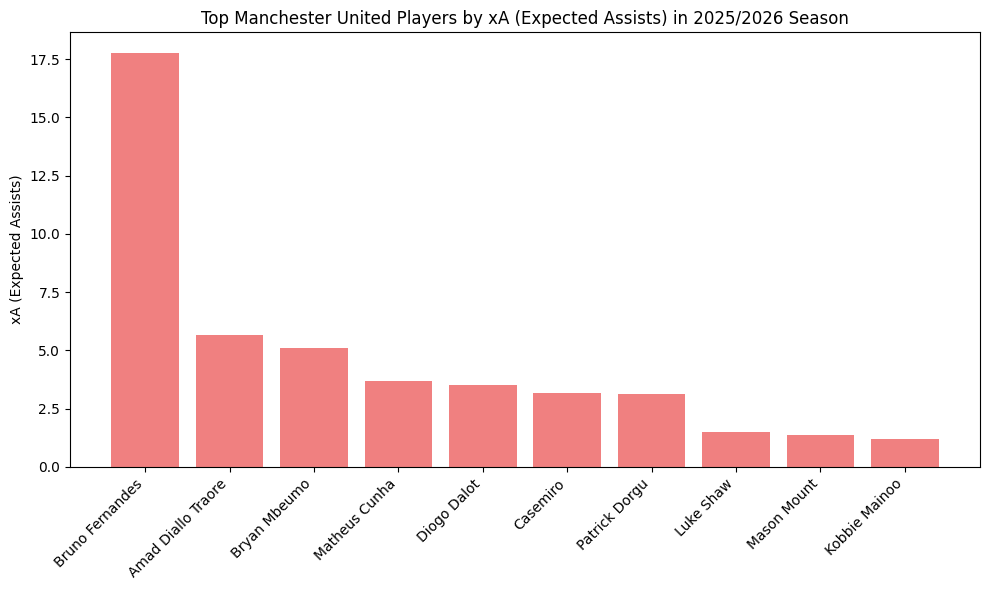

In [31]:
#ranking players by xG and xA
xg_col = "xg"
xa_col = "xa"

top_players_by_xG = (man_utd_data[man_utd_data["minutes"] > 1000]
.sort_values(xg_col, ascending=False)
.head(10))

plt.figure(figsize=(10, 6))
plt.bar(top_players_by_xG["player"], top_players_by_xG["xg"], color="royalblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("xG (Expected Goals)")
plt.title("Top Manchester United Players by xG (Expected Goals) in 2025/2026 Season")
plt.tight_layout()
plt.show()

top_players_by_xA = (man_utd_data[man_utd_data["minutes"] > 1000]
.sort_values(xa_col, ascending=False)
.head(10))

plt.figure(figsize=(10, 6))
plt.bar(top_players_by_xA["player"], top_players_by_xA["xa"], color="lightcoral")
plt.xticks(rotation=45, ha="right")
plt.ylabel("xA (Expected Assists)")
plt.title("Top Manchester United Players by xA (Expected Assists) in 2025/2026 Season")
plt.tight_layout()
plt.show()


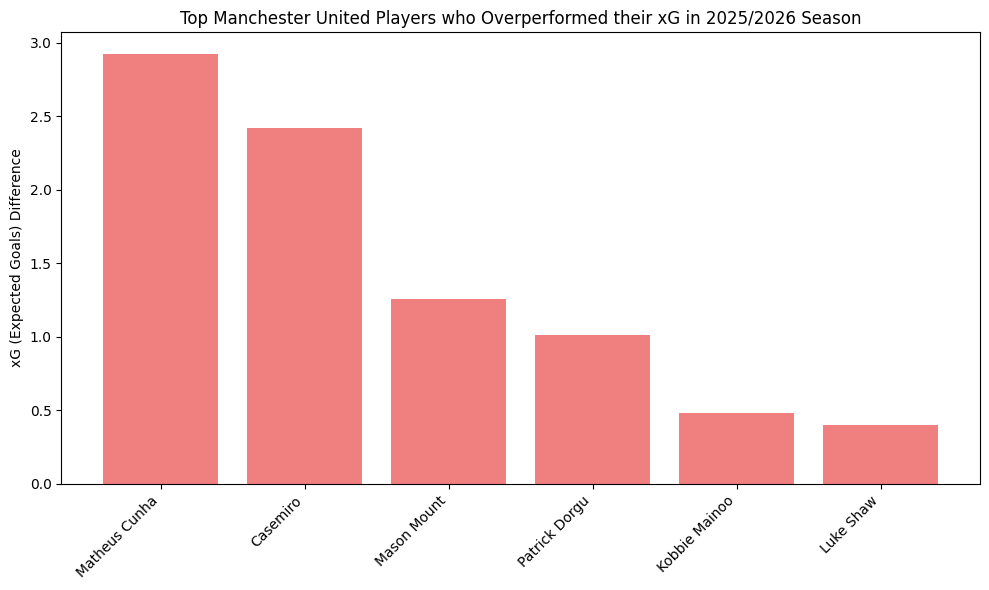

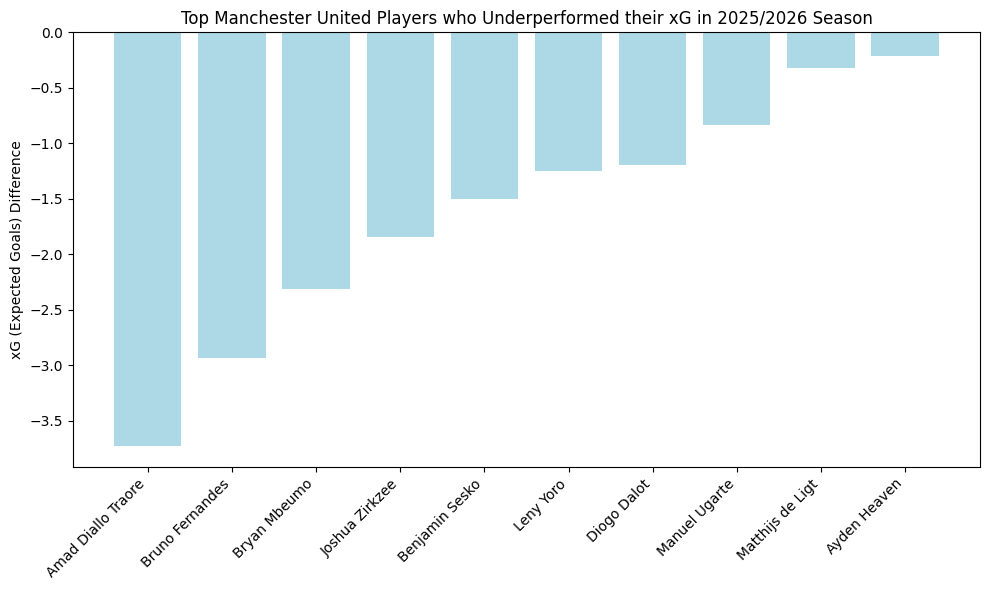

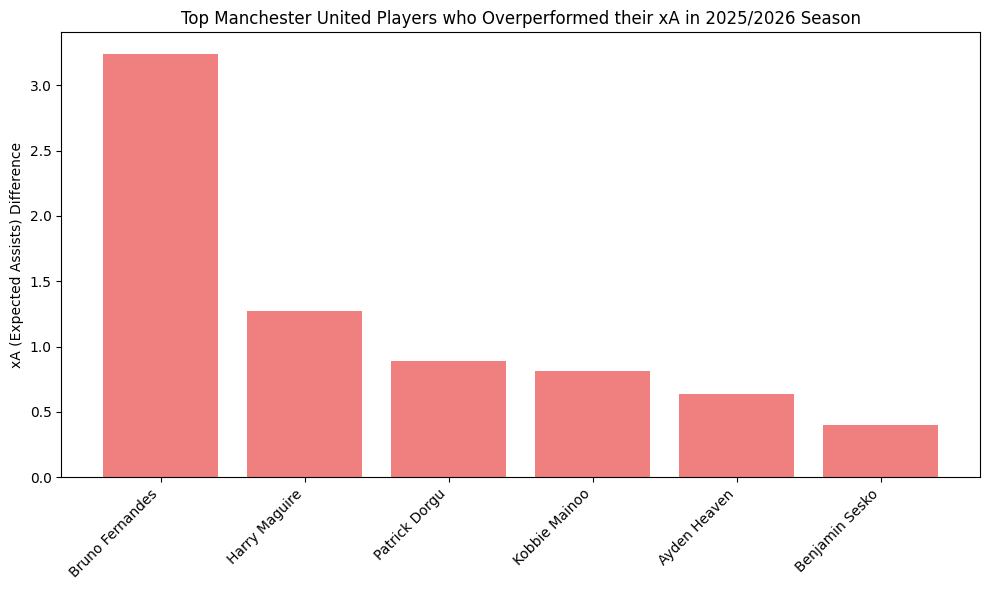

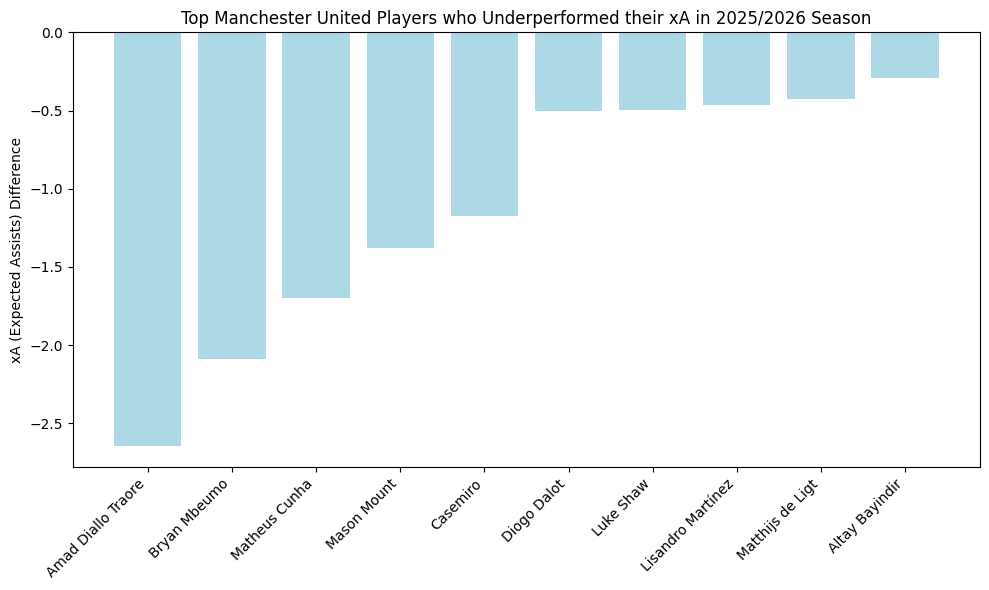

In [32]:
#checking who underperformed and overperformed their xG and xA
man_utd_data["xg_diff"] = (
    man_utd_data["goals"] - man_utd_data["xg"]
)

overperformers_xg = (man_utd_data[man_utd_data["xg_diff"] > 0]
                    .sort_values("xg_diff", ascending=False)
                    .head(10))

plt.figure(figsize=(10, 6))
plt.bar(overperformers_xg["player"], overperformers_xg["xg_diff"], color="lightcoral")
plt.xticks(rotation=45, ha="right")
plt.ylabel("xG (Expected Goals) Difference")
plt.title("Top Manchester United Players who Overperformed their xG in 2025/2026 Season")
plt.tight_layout()
plt.show()

underperformers_xg = (man_utd_data[man_utd_data["xg_diff"] < 0]
                     .sort_values("xg_diff", ascending=True)
                     .head(10))

plt.figure(figsize=(10, 6))
plt.bar(underperformers_xg["player"], underperformers_xg["xg_diff"], color="lightblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("xG (Expected Goals) Difference")
plt.title("Top Manchester United Players who Underperformed their xG in 2025/2026 Season")
plt.tight_layout()
plt.show()

man_utd_data["xa_diff"] = (
    man_utd_data["assists"] - man_utd_data["xa"]
)

overperformers_xa = (man_utd_data[man_utd_data["xa_diff"] > 0]
                    .sort_values("xa_diff", ascending=False)
                    .head(10))

plt.figure(figsize=(10, 6))
plt.bar(overperformers_xa["player"], overperformers_xa["xa_diff"], color="lightcoral")
plt.xticks(rotation=45, ha="right")
plt.ylabel("xA (Expected Assists) Difference")
plt.title("Top Manchester United Players who Overperformed their xA in 2025/2026 Season")
plt.tight_layout()
plt.show()

underperformers_xa = (man_utd_data[man_utd_data["xa_diff"] < 0]
                     .sort_values("xa_diff", ascending=True)
                     .head(10))

plt.figure(figsize=(10, 6))
plt.bar(underperformers_xa["player"], underperformers_xa["xa_diff"], color="lightblue")
plt.xticks(rotation=45, ha="right") 
plt.ylabel("xA (Expected Assists) Difference")
plt.title("Top Manchester United Players who Underperformed their xA in 2025/2026 Season")
plt.tight_layout()
plt.show()